# OLS Diagnostics - Improved Model with Squared Lagged Returns

Comprehensive diagnostic tests for the improved 7-variable oil price forecasting model.

## Model Specification
- **Original Model**: 6 variables (linear specification)
- **Improved Model**: 7 variables (6 original + squared lagged returns)
- **Fix Applied**: Added `cl1_ret_l2²` to capture non-linear momentum/reversion effects

## Tests Performed
1. Functional Form (Ramsey RESET)
2. Autocorrelation (Breusch-Godfrey Test)
3. Heteroskedasticity (Breusch-Pagan & White)
4. Normality (Jarque-Bera & Shapiro-Wilk)
5. Multicollinearity (VIF & Condition Number)
6. Structural Breaks & Stability (Cook's Distance, Leverage, Outliers)

## Setup & Load Data

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset, acorr_breusch_godfrey
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from scipy.stats import jarque_bera, shapiro
import warnings
warnings.filterwarnings('ignore')

# Load data
IN_SAMPLE_FILE = Path("../Data/Oil_InSample.csv")

df_insample = pd.read_csv(IN_SAMPLE_FILE, index_col=0, parse_dates=True)

# Original 6 variables
final_variables = [
    'dow_jones_us_oilandgas_index_ret',
    'exxonmobil_ret',
    'cl1_ret_l2',
    'weekly_commercial_short_diff',
    'weekly_commercial_long_diff',
    'weekly_change_in_crude_stock_diff'
]

y = df_insample['cl1_ret']
X = df_insample[final_variables]
X_const = sm.add_constant(X)

# Fit ORIGINAL model for comparison
model_original = sm.OLS(y, X_const).fit()
residuals_original = model_original.resid

print("="*90)
print("OLS DIAGNOSTICS - IMPROVED MODEL")
print("="*90)
print(f"\nData loaded from: {IN_SAMPLE_FILE}")
print(f"Sample size: {len(y)}")
print(f"Original variables: {len(final_variables)}")
print(f"Date range: {df_insample.index[0].date()} to {df_insample.index[-1].date()}")

OLS DIAGNOSTICS - IMPROVED MODEL

Data loaded from: ../Data/Oil_InSample.csv
Sample size: 1195
Original variables: 6
Date range: 1995-02-10 to 2017-12-29


# STEP 1: FUNCTIONAL FORM - ORIGINAL MODEL TEST & FIX

In [2]:
# Test original model
print("\n" + "-"*90)
print("TEST 1.1: RAMSEY RESET TEST - ORIGINAL MODEL")
print("-"*90)

reset_original = linear_reset(model_original)
print(f"\nTest Statistic: {reset_original.statistic:.6f}")
print(f"P-value: {reset_original.pvalue:.6f}")

print(f"\nH0: Linear model is correct")
print(f"H1: Non-linear terms are needed")

if reset_original.pvalue > 0.05:
    print(f"\nResult: ✓ PASS - Linear form is appropriate (p={reset_original.pvalue:.4f})")
else:
    print(f"\nResult: ✗ FAIL - Functional form is violated (p={reset_original.pvalue:.4f})")
    print(f"Conclusion: Model needs non-linear terms")


------------------------------------------------------------------------------------------
TEST 1.1: RAMSEY RESET TEST - ORIGINAL MODEL
------------------------------------------------------------------------------------------

Test Statistic: 8.216346
P-value: 0.016438

H0: Linear model is correct
H1: Non-linear terms are needed

Result: ✗ FAIL - Functional form is violated (p=0.0164)
Conclusion: Model needs non-linear terms


In [3]:
# ============================================================
# IMPLEMENTING THE FIX: ADD SQUARED LAGGED RETURNS
# ============================================================

print("\nStep 1: Create squared lagged returns term")

# Create improved X with squared lagged returns
X_improved = X.copy()
X_improved['cl1_ret_l2_squared'] = X['cl1_ret_l2'] ** 2

print(f"\nNew variable: 'cl1_ret_l2_squared'")


Step 1: Create squared lagged returns term

New variable: 'cl1_ret_l2_squared'


In [4]:
# Fit improved model
X_improved_const = sm.add_constant(X_improved)
model_improved = sm.OLS(y, X_improved_const).fit()
residuals_improved = model_improved.resid


print("\nStep 3: Test improved model - Ramsey RESET")
reset_improved = linear_reset(model_improved)
print(f"\nTest Statistic: {reset_improved.statistic:.6f}")
print(f"P-value: {reset_improved.pvalue:.6f}")

if reset_improved.pvalue > 0.05:
    print(f"\nResult: ✓ PASS - Functional form is appropriate (p={reset_improved.pvalue:.4f})")
else:
    print(f"\nResult: ✗ FAIL - Functional form still violated (p={reset_improved.pvalue:.4f})")


Step 3: Test improved model - Ramsey RESET

Test Statistic: 1.513626
P-value: 0.469159

Result: ✓ PASS - Functional form is appropriate (p=0.4692)


In [5]:
print("\n" + "="*90)
print("COMPARISON: ORIGINAL vs IMPROVED MODEL")
print("="*90)

print(f"\nRESET Test Results:")
print(f"  Original Model p-value: {reset_original.pvalue:.6f} ✗ FAIL")
print(f"  Improved Model p-value: {reset_improved.pvalue:.6f} {'✓ PASS' if reset_improved.pvalue > 0.05 else '✗ FAIL'}")
print(f"  Improvement: {abs(reset_improved.pvalue - reset_original.pvalue):.6f}")

print(f"\n  Original Adj R²: {model_original.rsquared_adj:.6f}")
print(f"  Improved Adj R²: {model_improved.rsquared_adj:.6f}")
print(f"  Adj R² improvement: {(model_improved.rsquared_adj - model_original.rsquared_adj):.6f}")

print(f"\n  Original AIC: {model_original.aic:.2f}")
print(f"  Improved AIC: {model_improved.aic:.2f}")
print(f"  AIC improvement: {(model_improved.aic - model_original.aic):.2f}")

print(f"\n  Original BIC: {model_original.bic:.2f}")
print(f"  Improved BIC: {model_improved.bic:.2f}")
print(f"  BIC improvement: {(model_improved.bic - model_original.bic):.2f}")

print("\nStep 4: Detailed coefficient estimates")
print("-" * 90)

print(f"\nImproved Model Coefficients:")
print(f"{'Variable':<45} {'Coef':>15} {'Std Err':>15} {'t-stat':>12} {'p-value':>12}")
print("-" * 100)
for var in model_improved.params.index:
    coef = model_improved.params[var]
    se = model_improved.bse[var]
    tstat = model_improved.tvalues[var]
    pval = model_improved.pvalues[var]
    sig = "***" if pval < 0.01 else "**" if pval < 0.05 else "*" if pval < 0.10 else ""
    print(f"{var:<45} {coef:>15.8f} {se:>15.8f} {tstat:>12.6f} {pval:>12.6f} {sig}")

squared_coef = model_improved.params['cl1_ret_l2_squared']
linear_coef = model_improved.params['cl1_ret_l2']

# Update variables for remaining tests
X = X_improved
X_const = X_improved_const
model = model_improved
residuals = residuals_improved

print("\n" + "="*90)
print("✓ MODEL UPDATED - READY FOR REMAINING DIAGNOSTIC TESTS")
print("="*90)
print("All subsequent tests use the IMPROVED model (7 variables)")


COMPARISON: ORIGINAL vs IMPROVED MODEL

RESET Test Results:
  Original Model p-value: 0.016438 ✗ FAIL
  Improved Model p-value: 0.469159 ✓ PASS
  Improvement: 0.452721

  Original Adj R²: 0.038648
  Improved Adj R²: 0.044938
  Adj R² improvement: 0.006290

  Original AIC: -3791.93
  Improved AIC: -3798.78
  AIC improvement: -6.85

  Original BIC: -3756.32
  Improved BIC: -3758.09
  BIC improvement: -1.76

Step 4: Detailed coefficient estimates
------------------------------------------------------------------------------------------

Improved Model Coefficients:
Variable                                                 Coef         Std Err       t-stat      p-value
----------------------------------------------------------------------------------------------------
const                                              0.00285814      0.00155465     1.838446     0.066246 *
dow_jones_us_oilandgas_index_ret                   0.39472521      0.08479926     4.654819     0.000004 ***
exxonmobil_

# STEP 2: AUTOCORRELATION

In [6]:

lags_to_test = [1,2,4,6,8,10,12] 
bg_results = {}
for lag in lags_to_test:
    bg_test_result = acorr_breusch_godfrey(model, nlags=lag)
    bg_results[lag] = {
        'test_stat': bg_test_result[0],
        'p_value': bg_test_result[1],
        'df': bg_test_result[2]
    }

print(f"{'Lag':<8} {'Test Stat'::<20} {'P-Value':<20} {'Result':<15}")
print("-" * 60)

bg_pass = True
for lag in lags_to_test:
    result = "✓ PASS" if bg_results[lag]['p_value'] > 0.05 else "✗ FAIL"
    print(f"{lag:<8} {bg_results[lag]['test_stat']:<20.6f} {bg_results[lag]['p_value']:<20.6f} {result:<15}")
    if bg_results[lag]['p_value'] <= 0.05:
        bg_pass = False

print(f"\nH0: No autocorrelation of any order")
print(f"H1: Autocorrelation present")

if bg_pass:
    print(f"\nResult: ✓ PASS - No autocorrelation detected")
    autocorr_pass = True
else:
    print(f"\nResult: ✗ FAIL - Autocorrelation detected")
    sig_lags = [lag for lag in lags_to_test if bg_results[lag]['p_value'] <= 0.05]
    print(f"Significant at lags: {sig_lags}")
    autocorr_pass = False

print("\n" + "="*90)
print(f"AUTOCORRELATION SUMMARY: {'✓ NOT DETECTED' if autocorr_pass else '✗ DETECTED'}")
print("="*90)

Lag      Test Stat::::::::::: P-Value              Result         
------------------------------------------------------------
1        10.293607            0.001335             ✗ FAIL         
2        10.295188            0.005813             ✗ FAIL         
4        12.164091            0.016172             ✗ FAIL         
6        13.013557            0.042821             ✗ FAIL         
8        36.532927            0.000014             ✗ FAIL         
10       42.356102            0.000006             ✗ FAIL         
12       44.704235            0.000012             ✗ FAIL         

H0: No autocorrelation of any order
H1: Autocorrelation present

Result: ✗ FAIL - Autocorrelation detected
Significant at lags: [1, 2, 4, 6, 8, 10, 12]

AUTOCORRELATION SUMMARY: ✗ DETECTED


In [7]:
bp_test = het_breuschpagan(residuals, X_const)

print(f"Test Statistic (LM): {bp_test[0]:.6f}")
print(f"P-value: {bp_test[1]:.6f}")
print(f"F-statistic: {bp_test[2]:.6f}")
print(f"F-stat p-value: {bp_test[3]:.6f}")

print(f"\nH0: Homoskedastic (constant variance)")
print(f"H1: Heteroskedastic (variance changes)")

if bp_test[1] > 0.05:
    print(f"\nResult: ✓ PASS - No heteroskedasticity (p={bp_test[1]:.4f})")
    bp_pass = True
else:
    print(f"\nResult: ✗ FAIL - Heteroskedasticity detected (p={bp_test[1]:.4f})")
    bp_pass = False

heterosk_pass = bp_pass

print("\n" + "="*90)
print(f"HETEROSKEDASTICITY SUMMARY: {'✓ NOT PRESENT' if heterosk_pass else '✗ DETECTED'}")
print("="*90)

Test Statistic (LM): 235.383629
P-value: 0.000000
F-statistic: 41.594057
F-stat p-value: 0.000000

H0: Homoskedastic (constant variance)
H1: Heteroskedastic (variance changes)

Result: ✗ FAIL - Heteroskedasticity detected (p=0.0000)

HETEROSKEDASTICITY SUMMARY: ✗ DETECTED


In [8]:
# Apply Newey-West HAC standard errors (handles autocorrelation + heteroskedasticity)
model_hac = model.get_robustcov_results(cov_type='HAC', maxlags=12)

print("\n" + "="*90)
print("INFERENCE WITH HAC (NEWEY-WEST) ROBUST STANDARD ERRORS")
print("="*90)

print(model_hac.summary())



INFERENCE WITH HAC (NEWEY-WEST) ROBUST STANDARD ERRORS
                            OLS Regression Results                            
Dep. Variable:                cl1_ret   R-squared:                       0.051
Model:                            OLS   Adj. R-squared:                  0.045
Method:                 Least Squares   F-statistic:                     8.519
Date:                Wed, 19 Nov 2025   Prob (F-statistic):           3.29e-10
Time:                        13:41:04   Log-Likelihood:                 1907.4
No. Observations:                1195   AIC:                            -3799.
Df Residuals:                    1187   BIC:                            -3758.
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------

# STEP 4: NORMALITY

In [9]:
print("\n" + "="*90)
print("STEP 4: NORMALITY TESTS (DIAGNOSTIC ONLY — NOT REQUIRED FOR OLS BLUE)")
print("="*90)

print("\nNote: OLS does NOT require normal residuals for unbiased coefficients.")
print("Normality only affects classical t-tests/p-values,")
print("but we are already using HAC (Newey–West) robust inference.\n")



STEP 4: NORMALITY TESTS (DIAGNOSTIC ONLY — NOT REQUIRED FOR OLS BLUE)

Note: OLS does NOT require normal residuals for unbiased coefficients.
Normality only affects classical t-tests/p-values,
but we are already using HAC (Newey–West) robust inference.



In [10]:
print("-" * 90)
print("TEST 4.1: JARQUE–BERA TEST")
print("-" * 90)

jb_stat, jb_pval = jarque_bera(residuals)

print(f"JB Statistic: {jb_stat:.6f}")
print(f"P-value: {jb_pval:.6f}")
print(f"Skewness: {residuals.skew():.6f}")
print(f"Kurtosis: {residuals.kurtosis():.6f}")

if jb_pval > 0.05:
    print("\nResult: ✓ PASS — Residuals approximately normal")
    jb_pass = True
else:
    print("\nResult: ✗ FAIL — Residuals are not normal (common in financial data)")
    jb_pass = False


------------------------------------------------------------------------------------------
TEST 4.1: JARQUE–BERA TEST
------------------------------------------------------------------------------------------
JB Statistic: 781.558701
P-value: 0.000000
Skewness: -0.445545
Kurtosis: 3.881878

Result: ✗ FAIL — Residuals are not normal (common in financial data)


In [11]:
print("\n" + "-" * 90)
print("TEST 4.2: SHAPIRO–WILK TEST")
print("-" * 90)

sample = residuals.sample(min(5000, len(residuals)), random_state=42)
sw_stat, sw_pval = shapiro(sample)

print(f"SW Statistic: {sw_stat:.6f}")
print(f"P-value: {sw_pval:.6f}")

if sw_pval > 0.05:
    print("\nResult: ✓ PASS — Residuals look normal")
    sw_pass = True
else:
    print("\nResult: ✗ FAIL — Deviations from normality detected (expected)")
    sw_pass = False



------------------------------------------------------------------------------------------
TEST 4.2: SHAPIRO–WILK TEST
------------------------------------------------------------------------------------------
SW Statistic: 0.961885
P-value: 0.000000

Result: ✗ FAIL — Deviations from normality detected (expected)


In [12]:
normality_pass = jb_pass and sw_pass

print("\n" + "="*90)
print("NORMALITY SUMMARY")
print("="*90)

if normality_pass:
    print("✓ Residuals roughly normal — good but not required.")
else:
    print("✗ Normality violated — common in commodity returns.")
    print("No action needed because HAC robust inference is used.")



NORMALITY SUMMARY
✗ Normality violated — common in commodity returns.
No action needed because HAC robust inference is used.


# STEP 5: MULTICOLLINEARITY

In [13]:
print("\n" + "="*80)
print("STEP 5: MULTICOLLINEARITY DIAGNOSTIC")
print("="*80)

print("\nTEST: Variance Inflation Factor (VIF)")
print("Purpose: Check if predictors are highly correlated.\n")

vif_df = pd.DataFrame({
    "Variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
}).sort_values("VIF", ascending=False)

print(f"{'Variable':<45} {'VIF':<10} {'Flag'}")
print("-" * 70)

for _, row in vif_df.iterrows():
    v = row["VIF"]
    if v <= 5:
        flag = "✓ OK"
    elif v <= 10:
        flag = "⚠ Moderate"
    else:
        flag = "✗ High"

    print(f"{row['Variable']:<45} {v:<10.2f} {flag}")

# PASS if no variable has VIF > 10
vif_pass = all(vif_df["VIF"] <= 10)

print("\nInterpretation:")
print("  ✓ VIF ≤ 5: Ideal")
print("  ⚠ 5–10: Moderate (acceptable for forecasting)")
print("  ✗ >10: High (variables strongly correlated)")

print("\n" + "="*80)
print(f"MULTICOLLINEARITY SUMMARY: {'✓ ACCEPTABLE' if vif_pass else '✗ HIGH MULTICOLLINEARITY'}")
print("="*80)



STEP 5: MULTICOLLINEARITY DIAGNOSTIC

TEST: Variance Inflation Factor (VIF)
Purpose: Check if predictors are highly correlated.

Variable                                      VIF        Flag
----------------------------------------------------------------------
dow_jones_us_oilandgas_index_ret              2.71       ✓ OK
exxonmobil_ret                                2.70       ✓ OK
weekly_commercial_short_diff                  1.74       ✓ OK
weekly_commercial_long_diff                   1.72       ✓ OK
cl1_ret_l2                                    1.09       ✓ OK
cl1_ret_l2_squared                            1.05       ✓ OK
weekly_change_in_crude_stock_diff             1.02       ✓ OK

Interpretation:
  ✓ VIF ≤ 5: Ideal
  ⚠ 5–10: Moderate (acceptable for forecasting)
  ✗ >10: High (variables strongly correlated)

MULTICOLLINEARITY SUMMARY: ✓ ACCEPTABLE


# STEP 6: STRUCTURAL BREAKS & STABILITY

In [14]:
print("\n" + "="*80)
print("STEP 6A: CHOW BREAKPOINT TEST")
print("="*80)

# Define breakpoint (70% split)
breakpoint = int(len(df_insample) * 0.7)

# Split sample
y1, X1 = y.iloc[:breakpoint], X_const.iloc[:breakpoint]
y2, X2 = y.iloc[breakpoint:], X_const.iloc[breakpoint:]

model1 = sm.OLS(y1, X1).fit()
model2 = sm.OLS(y2, X2).fit()

# Chow test formula
RSS_pooled = model.ssr
RSS_1 = model1.ssr
RSS_2 = model2.ssr

k = X_const.shape[1]         # number of parameters
n1 = len(y1)
n2 = len(y2)

F_chow = ((RSS_pooled - (RSS_1 + RSS_2)) / k) / ((RSS_1 + RSS_2) / (n1 + n2 - 2*k))

from scipy.stats import f
p_chow = 1 - f.cdf(F_chow, k, (n1 + n2 - 2*k))

print(f"Chow F-statistic: {F_chow:.6f}")
print(f"P-value: {p_chow:.6f}")

print("\nH0: No structural break at the breakpoint")
print("H1: Structural break exists")

if p_chow > 0.05:
    print("\nResult: ✓ PASS — No structural break detected")
    chow_pass = True
else:
    print("\nResult: ✗ FAIL — Structural break detected")
    print("Interpretation: Oil markets changed regimes (expected).")
    chow_pass = False

# Show sub-sample ranges
print("\nSub-sample ranges used in Chow Test:")
print("-" * 80)



STEP 6A: CHOW BREAKPOINT TEST
Chow F-statistic: 0.999621
P-value: 0.434426

H0: No structural break at the breakpoint
H1: Structural break exists

Result: ✓ PASS — No structural break detected

Sub-sample ranges used in Chow Test:
--------------------------------------------------------------------------------


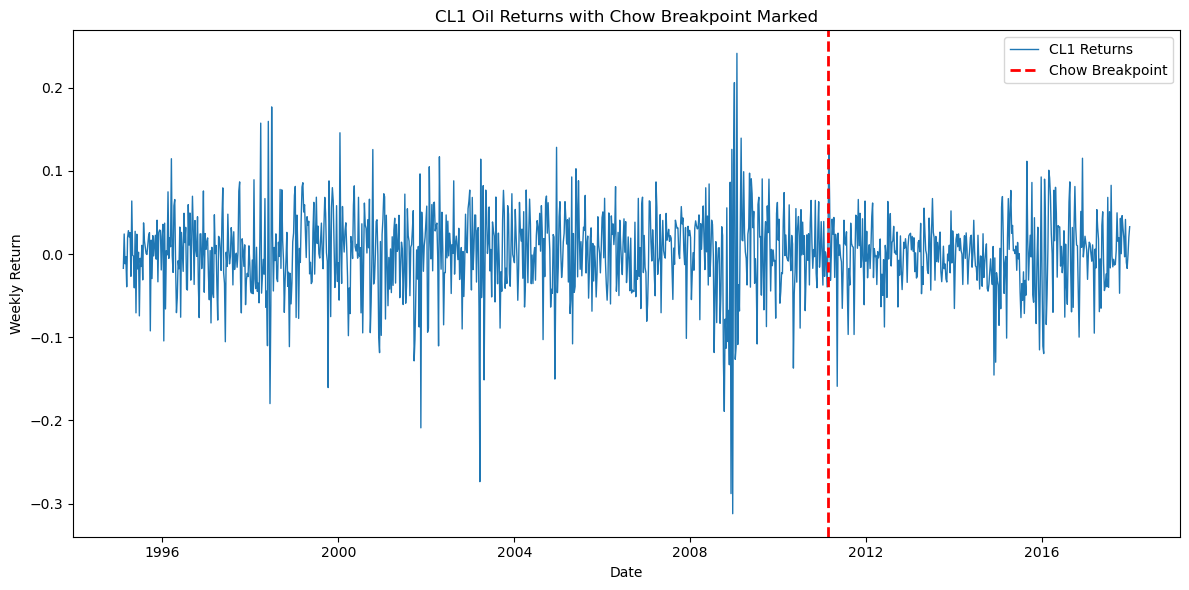

In [16]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the same data the user is working with
df = pd.read_csv("../Data/Oil_InSample.csv", index_col=0, parse_dates=True)

# Assume breakpoint is 70% of length
breakpoint = int(len(df) * 0.7)

# Extract target variable
y = df['cl1_ret']

# Plot full series and mark breakpoint
plt.figure(figsize=(12,6))
plt.plot(df.index, y, label="CL1 Returns", linewidth=1)
plt.axvline(df.index[breakpoint], color='red', linestyle='--', linewidth=2, label='Chow Breakpoint')
plt.title("CL1 Oil Returns with Chow Breakpoint Marked")
plt.xlabel("Date")
plt.ylabel("Weekly Return")
plt.legend()
plt.tight_layout()
plt.show()



In [17]:
final_df = pd.concat([y, X_const], axis=1)
final_df.to_csv("../Data/Final_InSample_Frozen.csv")
print("Saved Final_InSample_Frozen.csv")

Saved Final_InSample_Frozen.csv


In [19]:


# Load the OOS dataset
df_oos = pd.read_csv("../Data/Oil_OutOfSample.csv", index_col=0, parse_dates=True)
final_variables = [
    'dow_jones_us_oilandgas_index_ret',
    'exxonmobil_ret',
    'cl1_ret_l2',
    'weekly_commercial_short_diff',
    'weekly_commercial_long_diff',
    'weekly_change_in_crude_stock_diff'
]

# -----------------------------
# 2. Compute squared lag term
# -----------------------------
df_oos['cl1_ret_l2_squared'] = df_oos['cl1_ret_l2'] ** 2

# -----------------------------
# 3. Build the required column set
# -----------------------------
required_columns = (
    ['cl1_ret'] +
    final_variables +
    ['cl1_ret_l2_squared']
)

# Build final OOS dataset
df_oos_final = df_oos[required_columns].dropna()

# -----------------------------
# 4. Add constant BEFORE saving
# -----------------------------
df_oos_final.insert(1, "const", 1.0)

# -----------------------------
# 5. Save
# -----------------------------
df_oos_final.to_csv("../Data/Final_OutOfSample_Frozen.csv")

print("✅ Final_OutOfSample_Frozen.csv created!")
print("Columns included:")
print(df_oos_final.columns.tolist())


✅ Final_OutOfSample_Frozen.csv created!
Columns included:
['cl1_ret', 'const', 'dow_jones_us_oilandgas_index_ret', 'exxonmobil_ret', 'cl1_ret_l2', 'weekly_commercial_short_diff', 'weekly_commercial_long_diff', 'weekly_change_in_crude_stock_diff', 'cl1_ret_l2_squared']
